<a href="https://colab.research.google.com/github/PedroFisica200/C-digo-do-trabalho-de-F-sica-Computacional/blob/main/Deposi%C3%A7%C3%A3oDoseMCPedroMinasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

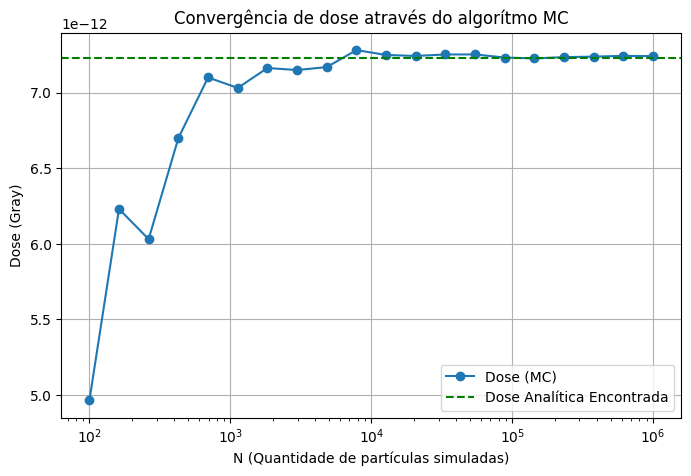

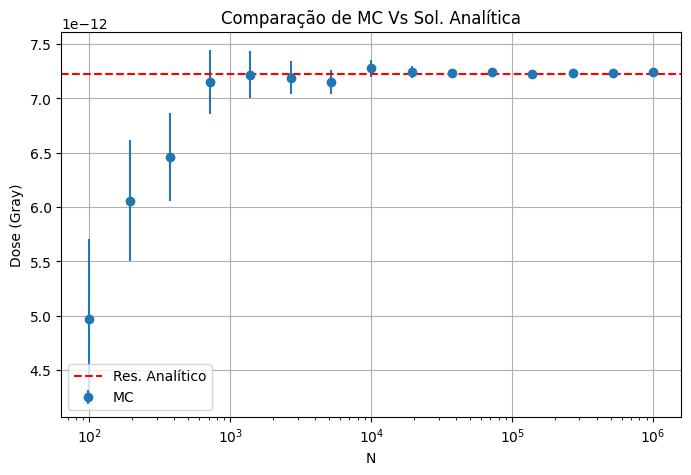

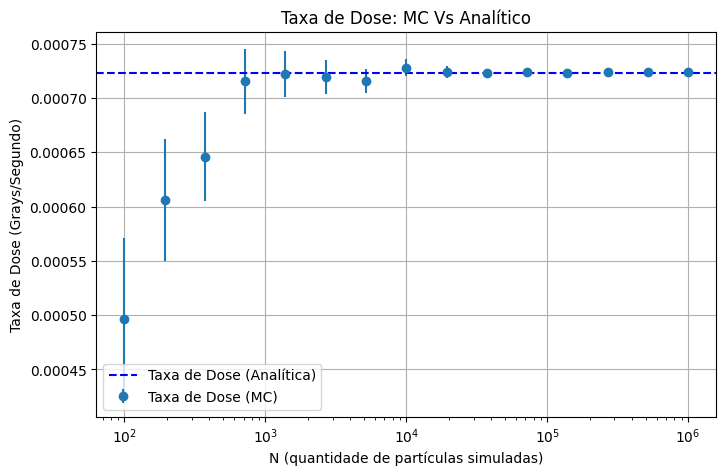

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# ESTABELECENDO A FUNÇÃO DE MONTE CARLO
# ---------------------------------------
def dose_de_monte_carlo(N, energia_MeV, massa_kg, mu, espessura_m, seed=11037):
    # Estabelecendo o RNG:
    rng = np.random.default_rng(seed)
    # Estabelecendo a conversão de MeV pra Joules
    # Isso se dá pois a dose depositada em um meio é dada em função da
    # Energia por kilograma
    # 1 MeV = 1.602176634e-13
    energia_J = energia_MeV * 1.602176634e-13
    # Estabelecendo a profundidade percorrida até a interação
    profundidade = rng.exponential(1/mu, size=N)
    # Se a interação ocorre dentro do detector, toda a energia é depositada
    interacao = profundidade <= espessura_m
    energia_depositada = interacao.astype(float) * energia_J
    # Cálculo da dose (medida em Gray/Partícula)
    dose = energia_depositada.mean() / massa_kg
    return dose, energia_depositada.mean(), energia_depositada.std()
# ------------------------------------------------------------
# ESTABELECENDO OS PARÂMETROS DO CÓDIGO
# Todos os valores usados são arbitrários e escolhidos a dedo
# ------------------------------------------------------------

energia_MeV = 5.0   # Energia incidente em MeV
massa_kg = 0.05    # Massa do vol. onde a dose vai ser calc. em kg
mu = 20     # Coeficiente de atenuação linear, geralmente dado em m^-1
espessura_m = 0.03      # Espessura do volume penetrado em metros
Fluxo = 1e8     # Fluxo total de partícula incidentes na superfície do detector

# ---------------------------------------
# ESTABELECENDO UMA SOLUÇÃO ANALÍTICA PRA COMPARAÇÃO FUTURA
E0 = energia_MeV * 1.602176634e-13
E_media_analitica = E0 * (1 - np.exp(-mu * espessura_m))
dose_analitica = E_media_analitica / massa_kg
taxa_analitica = dose_analitica * Fluxo
# ---------------------------------------
# A) ESTABELECENDO O GRÁFICO DA DOSE CONVERGENTE
# ---------------------------------------
Ns = np.logspace(2, 6, 20, dtype=int)
valores_dose = []
for N in Ns:
    dose, _, _ = dose_de_monte_carlo(
        N=N,
        energia_MeV=energia_MeV,
        massa_kg=massa_kg,
        mu=mu,
        espessura_m=espessura_m,
    )
    valores_dose.append(dose)
plt.figure(figsize=(8,5))
plt.plot(Ns, valores_dose, "o-", label="Dose (MC)")
plt.axhline(dose_analitica, color="green", linestyle="--", label="Dose Analítica Encontrada")
plt.xscale("log")
plt.xlabel("N (Quantidade de partículas simuladas)")
plt.ylabel("Dose (Gray)")
plt.title("Convergência de dose através do algorítmo MC")
plt.legend()
plt.grid(True)
plt.show()

# ---------------------------------------------------
# B) ESTABELECENDO A COMPARAÇÃO DE MC X MC ANALÍTICO
# ---------------------------------------------------
Ns = np.logspace(2, 6, 15, dtype=int)
dose_MC = []
erro_MC = []
for N in Ns:
    dose, EMedia, stdE = dose_de_monte_carlo(
        N=N,
        energia_MeV=energia_MeV,
        massa_kg=massa_kg,
        mu=mu,
        espessura_m=espessura_m,
    )
    dose_MC.append(dose)
    erro_MC.append(stdE / np.sqrt(N) / massa_kg)
plt.figure(figsize=(8,5))
plt.errorbar(Ns, dose_MC, yerr=erro_MC, fmt="o", label="MC")
plt.axhline(dose_analitica, color="red", linestyle="--", label="Res. Analítico")
plt.xscale("log")
plt.xlabel("N")
plt.ylabel("Dose (Gray)")
plt.title("Comparação de MC Vs Sol. Analítica")
plt.legend()
plt.grid(True)
plt.show()
# -----------------------------------------------------------------
# C) ESTABELECENDO UM GRÁFICO COMPARANDO A TAXA Vs VAL. ANALÍTICO
# -----------------------------------------------------------------
Ns = np.logspace(2, 6, 15, dtype=int)
taxa_de_dose_MC = []
erro_MC = []
for N in Ns:
    dose, EMedia, stdE = dose_de_monte_carlo(
        N=N,
        energia_MeV=energia_MeV,
        massa_kg=massa_kg,
        mu=mu,
        espessura_m=espessura_m,
    )
# -----------------------------------------------------------
# Fórmula da taxa de dose é dada por: Dose * Fluxo
    taxa_de_dose_MC.append(dose * Fluxo)
# Convertemos a incerteza da média para taxa de dose.
    erro_MC.append((stdE / np.sqrt(N) / massa_kg) * Fluxo)
plt.figure(figsize=(8,5))
plt.errorbar(Ns, taxa_de_dose_MC, yerr=erro_MC, fmt="o", label="Taxa de Dose (MC)")
plt.axhline(taxa_analitica, color="blue", linestyle="--", label="Taxa de Dose (Analítica)")
plt.xscale("log")
plt.xlabel("N (quantidade de partículas simuladas)")
plt.ylabel("Taxa de Dose (Grays/Segundo)")
plt.title("Taxa de Dose: MC Vs Analítico")
plt.legend()
plt.grid(True)
plt.show()